# Power of a quantile breakpoint test under a bounded, heteroscedastic model

This notebook simulates data whose conditional $\tau^\star$-quantile is a piecewise-linear function of a predictor $X$ with known breakpoints. It then measures how often a calibrated test detects that the quantile curve is not a straight line.

- **Data.** The response $Y\in(0,1)$ is generated through logit → heteroscedastic Student-$t$ noise → expit, so the true quantile curve is known exactly.
- **Test.** Grid-search piecewise-linear quantile regression, the loss-improvement statistic $T_{\mathrm{loss}}$, and a critical value calibrated by simulation under the null.
- **Experiments.** Type-I error and power at a baseline sample size, then three power curves: against the size of the slope changes, against the sample size, and against how densely $X$ is sampled near the breakpoints.

The scenario (breakpoints, slope changes, noise, design of $X$) is set once in Section 0. Each power experiment in Sections 5–7 has its own grid at the top of its code cell.

**Workflow**

0. Settings
1. Data-generating process
2. Design check: the curve is the conditional $\tau^\star$-quantile
3. The detector: piecewise-linear quantile regression
4. Calibrated test at the baseline sample size
5. Power vs slope-change strength
6. Power vs sample size
7. Power vs sample density near the breakpoints
8. Notes

**Notation**

| Symbol | Meaning |
|---|---|
| $X$, $Y$ | predictor and response, $Y\in(0,1)$ |
| $\tau^\star$ | target conditional quantile |
| $m(x)$ | true conditional $\tau^\star$-quantile of $Y$ given $X=x$ |
| $K$ | number of breakpoints in the true curve |
| $\kappa_1<\dots<\kappa_K$ | breakpoint locations |
| $\delta_j$ | slope change at $\kappa_j$ (the strength of breakpoint $j$) |
| $\sigma(x)$; $Z$ | noise scale on the logit scale; centred Student-$t_\nu$ noise with $Q_Z(\tau^\star)=0$ |
| $\Psi$ | search window for fitted breakpoints |
| $w$, $p$ | half-width of the windows around the breakpoints; share of $X$ inside them (Section 7) |
| $\rho_\tau(u)=u\{\tau-\mathbf 1(u<0)\}$ | check (pinball) loss |
| $T_{\mathrm{loss}}$; $\widehat c_\alpha$; $\phi_\alpha$ | test statistic; calibrated critical value; decision (1 = reject $H_0$) |
| $R_{\mathrm{cal}}, R_{\mathrm{null}}, R_{\mathrm{alt}}$ | Monte Carlo replications for calibration, null validation, alternative |

## 0. Settings

Every setting of the scenario is in the cell below. Rerun the notebook from here after changing any of them.

- **True curve.** The number of breakpoints, their locations $\kappa_j$, and the slope change $\delta_j$ at each one. The intercept and slope left of the first breakpoint fix where the curve starts.
- **Noise.** The logit-scale scale $\sigma(x)$, given at the two ends of the $X$ range and linear in between, and the Student-$t$ degrees of freedom.
- **Design of $X$.** Its range and Beta shape. The default is uniform on $[0,1]$.
- **Test.** $\alpha$, the largest number of breakpoints the detector fits, the search window $\Psi$, the baseline sample size, replication counts and search rules.

With the default settings the whole notebook takes about 10 minutes on 12 cores. Set `RUN_MONTE_CARLO = False` to run only Sections 0–3.

Every figure is also saved to the `images/` folder next to this notebook as a 300-dpi PNG, numbered in the order it appears.

In [1]:
import os
import time
import hashlib
from pathlib import Path
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import linprog
from scipy.special import expit, logit
from joblib import Parallel, delayed
from IPython.display import display

# --- True conditional quantile curve m(x) ---
TAU_STAR      = 0.80             # m(x) is the true conditional tau*-quantile of Y
N_BREAKPOINTS = 2                # number of breakpoints K
KAPPAS        = (0.40, 0.70)     # breakpoint locations kappa_1 < ... < kappa_K
DELTAS        = (-0.90, 0.90)    # slope change at each breakpoint (strength)
BETA0, BETA1  = 0.65, -0.20      # intercept and slope left of the first breakpoint

# --- Noise: Y = expit(logit m(X) + sigma(X) Z) ---
SIGMA = (0.40, 0.60)             # logit-scale noise scale at the left and right end of X_RANGE, linear in between
DF_T  = 8                        # degrees of freedom of the Student-t noise Z

# --- Design of X ---
X_RANGE = (0.0, 1.0)             # support of X
X_BETA  = (1.0, 1.0)             # Beta shape of X on X_RANGE; (1, 1) is uniform

# --- Hypothesis test ---
ALPHA        = 0.05
K_TEST       = 2                 # the detector fits up to K_TEST breakpoints
KAPPA_WINDOW = (0.20, 0.85)      # search window Psi for fitted breakpoints
N_BASE       = 150               # baseline sample size (Sections 1-5)
R_CAL, R_NULL, R_ALT = 300, 300, 300   # Monte Carlo replications per phase

# --- Breakpoint search rules ---
MAX_GRID_POINTS = 41                   # candidate breakpoint locations per dataset
MIN_SIDE, MIN_SIDE_FRAC = 10, 0.15     # each segment needs h(n) = max(MIN_SIDE, ceil(MIN_SIDE_FRAC * n)) points
MIN_UNIQUE_PER_SEGMENT = 2
MIN_KAPPA_GAP = 0.0                    # minimum distance between two fitted breakpoints

# --- Run switches and output ---
RUN_MONTE_CARLO = True                 # Sections 4-7
IMAGE_DIR = Path('images')             # every figure is also saved here as a 300-dpi PNG
SEED   = 2026
N_JOBS = max(1, int(0.8 * os.cpu_count()))

assert N_BREAKPOINTS >= 1 and len(KAPPAS) == len(DELTAS) == N_BREAKPOINTS, \
    'KAPPAS and DELTAS need exactly N_BREAKPOINTS entries each.'
assert np.all(np.diff(KAPPAS) > 0), 'KAPPAS must be increasing.'
assert X_RANGE[0] <= KAPPA_WINDOW[0] < KAPPA_WINDOW[1] <= X_RANGE[1], 'KAPPA_WINDOW must lie inside X_RANGE.'
assert K_TEST >= 1, 'The detector needs K_TEST >= 1.'
if not KAPPA_WINDOW[0] <= min(KAPPAS) <= max(KAPPAS) <= KAPPA_WINDOW[1]:
    warnings.warn('Some true breakpoints lie outside the search window KAPPA_WINDOW.')

C_DATA, C_TRUE, C_NULL, C_FIT, C_BAND = '#157A8C', '#243746', '#657580', '#C13D43', '#8C969D'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18, 'axes.titleweight': 'bold',
    'figure.constrained_layout.use': True,
})
pd.set_option('display.precision', 4)


IMAGE_DIR.mkdir(exist_ok=True)


def save_figure(fig, name):
    """Save a figure as IMAGE_DIR/name.png at 300 dpi."""
    fig.savefig(IMAGE_DIR / f'{name}.png', dpi=300, bbox_inches='tight')


def rng_for(*labels):
    """Independent, reproducible random stream for a label tuple such as (phase, n, deltas, r)."""
    token = '|'.join(map(str, (SEED,) + labels)).encode()
    return np.random.default_rng(int.from_bytes(hashlib.sha256(token).digest()[:16], 'little'))


print(f'K = {N_BREAKPOINTS} breakpoints at {KAPPAS} with slope changes {DELTAS}; '
      f'tau* = {TAU_STAR}; sigma = {SIGMA}; t df = {DF_T}')
print(f'alpha = {ALPHA}, n = {N_BASE}, R_cal/R_null/R_alt = {R_CAL}/{R_NULL}/{R_ALT}, parallel jobs = {N_JOBS}')

K = 2 breakpoints at (0.4, 0.7) with slope changes (-0.9, 0.9); tau* = 0.8; sigma = (0.4, 0.6); t df = 8
alpha = 0.05, n = 150, R_cal/R_null/R_alt = 300/300/300, parallel jobs = 12


## 1. Data-generating process

### The bounded model

$$
Y=\operatorname{expit}\Big(\operatorname{logit}\big(m(X)\big)+\sigma(X)\,Z\Big),
\qquad Z=U-F^{-1}_{t_\nu}(\tau^\star),\quad U\sim t_\nu .
$$

The shift makes $Q_Z(\tau^\star)=0$. Since logit and expit are strictly increasing, quantiles pass straight through them:

$$
Q_{Y\mid X=x}(\tau^\star)
=\operatorname{expit}\Big(\operatorname{logit}\,m(x)+\sigma(x)\,Q_Z(\tau^\star)\Big)
=m(x).
$$

So $m(x)$ is **exactly** the conditional $\tau^\star$-quantile. Because expit maps $\mathbb R$ into $(0,1)$, every simulated $Y$ lies in $(0,1)$, with no clipping or redrawing.

### The true quantile curve

$$
m(x)=\beta_0+\beta_1x+\sum_{j=1}^{K}\delta_j\,(x-\kappa_j)_+,
\qquad (v)_+=\max(v,0).
$$

The slope is $\beta_1$ left of $\kappa_1$ and changes by $\delta_j$ at each $\kappa_j$, so segment $j+1$ has slope $\beta_1+\delta_1+\dots+\delta_j$. The curve must stay inside $(0,1)$ for the logit to exist; the code checks this.

**Null and alternative.** Under $H_0$ every $\delta_j=0$, which leaves the straight line $m_0(x)=\beta_0+\beta_1x$. The null keeps $\beta_0$, $\beta_1$, $\sigma(x)$ and the design of $X$; only the bends are removed.

### Noise scale

$$
\sigma(x)=\sigma_L+(\sigma_R-\sigma_L)\,\frac{x-x_{\min}}{x_{\max}-x_{\min}} .
$$

The noise is heteroscedastic in two ways. $\sigma(x)$ changes with $x$ on the logit scale, and the expit maps it back with local slope $m(1-m)$. On the $Y$ scale, near the target quantile,

$$
Y-m(x)\;\approx\;m(x)\{1-m(x)\}\,\sigma(x)\,Z .
$$

### Design of $X$

By default the $X_i$ are i.i.d. from a scaled Beta distribution:

$$
X=x_{\min}+(x_{\max}-x_{\min})\,B,\qquad B\sim\mathrm{Beta}(b_1,b_2).
$$

Section 7 re-weights this design to put more or less mass near the breakpoints. `draw_X` already supports that through `near_share` and `half_width`; the formula is given there.

In [2]:
Z_SHIFT = stats.t.ppf(TAU_STAR, DF_T)     # Z = U - Z_SHIFT has P(Z <= 0) = tau*
NULL_DELTAS = (0.0,) * N_BREAKPOINTS     # H0: no slope changes


def m_true(x, deltas=None):
    """True tau*-quantile curve m(x). deltas defaults to DELTAS; NULL_DELTAS gives the null line."""
    deltas = DELTAS if deltas is None else deltas
    x = np.asarray(x, float)
    return BETA0 + BETA1 * x + sum(d * np.maximum(x - k, 0) for d, k in zip(deltas, KAPPAS))


def sigma_fn(x):
    """Noise scale on the logit scale, linear from SIGMA[0] at x_min to SIGMA[1] at x_max."""
    t = (np.asarray(x, float) - X_RANGE[0]) / (X_RANGE[1] - X_RANGE[0])
    return SIGMA[0] + (SIGMA[1] - SIGMA[0]) * t


def base_X(size, rng):
    lo, hi = X_RANGE
    return lo + (hi - lo) * rng.beta(*X_BETA, size=size)


def near_breakpoints(x, half_width):
    """True where x lies within half_width of some breakpoint."""
    x = np.asarray(x, float)
    return (np.abs(x[:, None] - np.asarray(KAPPAS)[None, :]) <= half_width).any(axis=1)


def draw_X(n, rng, near_share=None, half_width=None):
    """n i.i.d. draws of X.

    near_share=None: the base design. Otherwise each draw falls within half_width of a breakpoint
    with probability near_share, keeping the base shape inside and outside those windows.
    """
    if near_share is None:
        return base_X(n, rng)
    n_near = rng.binomial(n, near_share)
    parts = []
    for count, inside in [(n_near, True), (n - n_near, False)]:
        kept = np.empty(0)
        while kept.size < count:                      # rejection sampling from the base design
            candidates = base_X(4 * count + 50, rng)
            kept = np.r_[kept, candidates[near_breakpoints(candidates, half_width) == inside]]
        parts.append(kept[:count])
    return rng.permutation(np.concatenate(parts))


def simulate(n, deltas=None, *, rng, near_share=None, half_width=None):
    """One dataset: Y = expit(logit m(X) + sigma(X) Z), always inside (0, 1)."""
    X = draw_X(n, rng, near_share, half_width)
    Z = rng.standard_t(DF_T, size=n) - Z_SHIFT
    Y = expit(logit(m_true(X, deltas)) + sigma_fn(X) * Z)
    return X, Y


def true_quantile(tau, x, deltas=None):
    """Exact conditional tau-quantile of Y given X = x, for any tau."""
    z = stats.t.ppf(tau, DF_T) - Z_SHIFT
    return expit(logit(m_true(x, deltas)) + sigma_fn(x) * z)


xx = np.linspace(*X_RANGE, 1000)
for deltas in (DELTAS, NULL_DELTAS):
    m = m_true(xx, deltas)
    assert (m > 0).all() and (m < 1).all(), f'm(x) leaves (0, 1) for slope changes {deltas}'

edges = np.r_[X_RANGE[0], KAPPAS, X_RANGE[1]]
display(pd.DataFrame(dict(segment=np.arange(1, N_BREAKPOINTS + 2), x_from=edges[:-1], x_to=edges[1:],
                          slope=BETA1 + np.r_[0, np.cumsum(DELTAS)],
                          m_at_start=m_true(edges[:-1]), m_at_end=m_true(edges[1:]))))

,segment,x_from,x_to,slope,m_at_start,m_at_end
0,1,0.0,0.4,-0.2,0.65,0.57
1,2,0.4,0.7,-1.1,0.57,0.24
2,3,0.7,1.0,-0.2,0.24,0.18


One simulated dataset under $H_1$ at the baseline sample size.

- The dark curve is the true $\tau^\star$-quantile $m(x)$, so about $100\,\tau^\star\%$ of the points fall below it.
- The dashed grey line is the null line $m_0(x)$.
- The thin dashed curves are the exact 10% and 90% conditional quantiles.
- The shaded band is the search window $\Psi$, and dotted verticals mark the breakpoints.

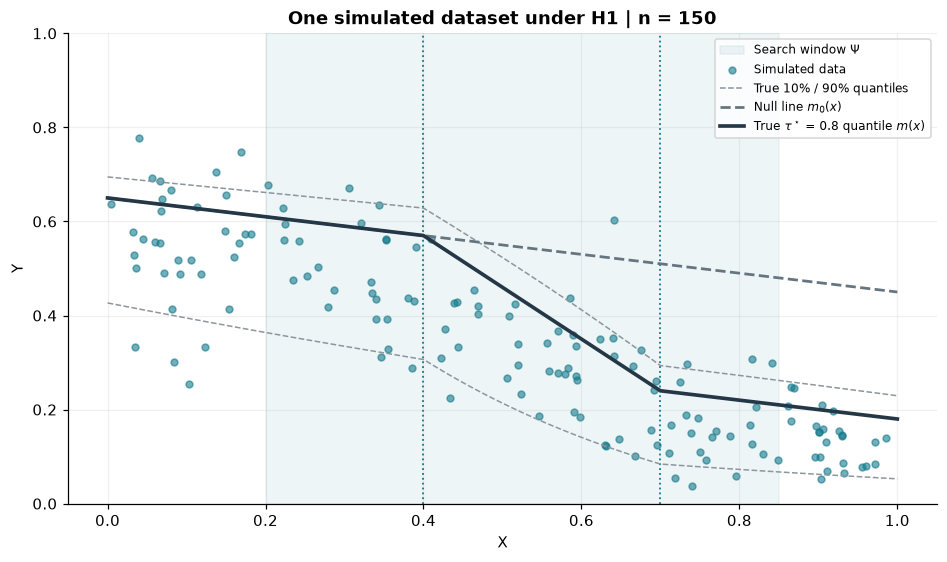

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5))
X, Y = simulate(N_BASE, rng=rng_for('illustration'))
ax.axvspan(*KAPPA_WINDOW, color=C_DATA, alpha=0.07, label=r'Search window $\Psi$')
for k in KAPPAS:
    ax.axvline(k, color=C_DATA, ls=':', lw=1.2)
ax.scatter(X, Y, s=20, alpha=0.6, color=C_DATA, label='Simulated data')
ax.plot(xx, true_quantile(0.10, xx), color=C_BAND, ls='--', lw=1)
ax.plot(xx, true_quantile(0.90, xx), color=C_BAND, ls='--', lw=1, label='True 10% / 90% quantiles')
ax.plot(xx, m_true(xx, NULL_DELTAS), color=C_NULL, ls='--', lw=1.8, label=r'Null line $m_0(x)$')
ax.plot(xx, m_true(xx), color=C_TRUE, lw=2.4, label=rf'True $\tau^\star$ = {TAU_STAR} quantile $m(x)$')
ax.set(xlabel='X', ylabel='Y', ylim=(0, 1), title=f'One simulated dataset under H1 | n = {N_BASE}')
ax.legend(fontsize=8, loc='upper right')
save_figure(fig, '01_simulated_data')
plt.show()

## 2. Design check: is $m(x)$ the true $\tau^\star$-quantile?

With a very large sample, the empirical $\tau^\star$-quantile inside narrow $X$ bins should trace $m(x)$, including every kink. The coverage should also be flat:

$$
P\{Y\le m(X)\mid X\}=\tau^\star\quad\text{in every bin.}
$$

The grey band on the right is $\pm2$ Monte Carlo standard errors, $\sqrt{\tau^\star(1-\tau^\star)/n_{\mathrm{bin}}}$.

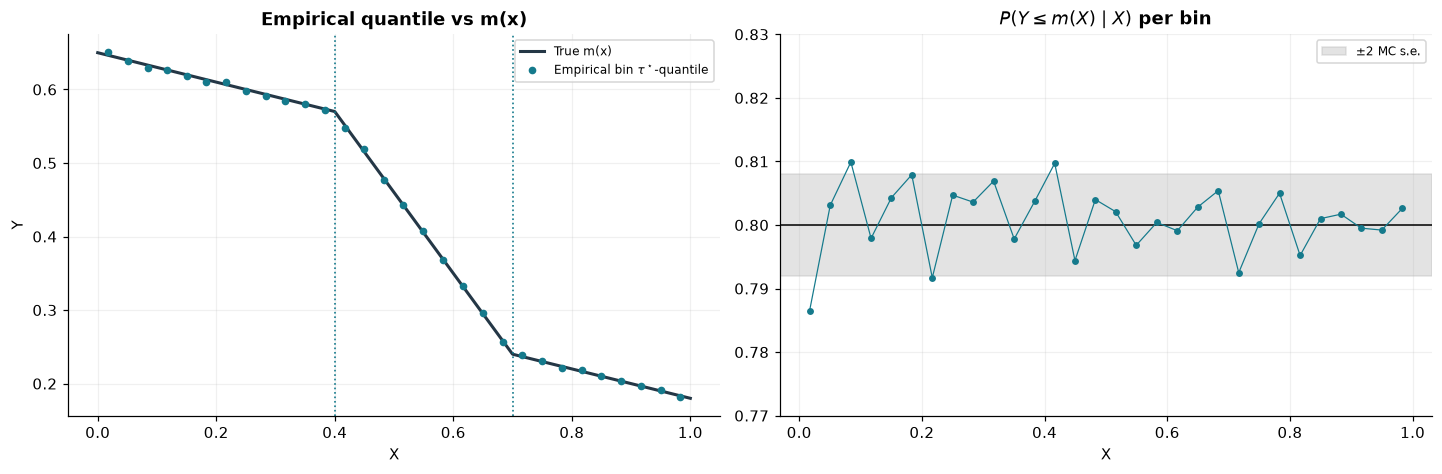

Overall P(Y <= m(X)) = 0.8010 (target 0.8); Y ranges over [0.0010, 0.9906], strictly inside (0, 1).


In [4]:
N_BIG, N_BINS = 300_000, 30
X, Y = simulate(N_BIG, rng=rng_for('design check'))
bins = np.array_split(np.argsort(X), N_BINS)              # equal-count X bins
mids = np.array([X[b].mean() for b in bins])
q_emp = np.array([np.quantile(Y[b], TAU_STAR) for b in bins])
cover = np.array([np.mean(Y[b] <= m_true(X[b])) for b in bins])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(xx, m_true(xx), color=C_TRUE, lw=2, label='True m(x)')
ax.plot(mids, q_emp, 'o', ms=4, color=C_DATA, label=r'Empirical bin $\tau^\star$-quantile')
for k in KAPPAS:
    ax.axvline(k, color=C_DATA, ls=':', lw=1.1)
ax.set(title='Empirical quantile vs m(x)', xlabel='X', ylabel='Y')
ax.legend(fontsize=8)

ax = axes[1]
se = np.sqrt(TAU_STAR * (1 - TAU_STAR) / (N_BIG / N_BINS))
ax.axhspan(TAU_STAR - 2 * se, TAU_STAR + 2 * se, color='#bbbbbb', alpha=0.4, label='±2 MC s.e.')
ax.axhline(TAU_STAR, color='black', lw=1)
ax.plot(mids, cover, 'o-', ms=3.5, lw=0.8, color=C_DATA)
ax.set(title=r'$P(Y \leq m(X) \mid X)$ per bin', xlabel='X', ylim=(TAU_STAR - 0.03, TAU_STAR + 0.03))
ax.legend(fontsize=8)
save_figure(fig, '02_design_check')
plt.show()
print(f'Overall P(Y <= m(X)) = {np.mean(Y <= m_true(X)):.4f} (target {TAU_STAR}); '
      f'Y ranges over [{Y.min():.4f}, {Y.max():.4f}], strictly inside (0, 1).')

## 3. The detector: piecewise-linear quantile regression

For $k=0,1,\dots,K_{\mathrm{test}}$ the detector computes the smallest check loss of a $k$-breakpoint fit:

$$
S_k(D_n)=\min_{(\kappa_1,\dots,\kappa_k)\in\Psi_k(D_n)}\;
\min_{\beta,\delta}\;
\sum_{i=1}^{n}\rho_{\tau^\star}\!\Big(Y_i-\beta_0-\beta_1X_i-\sum_{j=1}^{k}\delta_j(X_i-\kappa_j)_+\Big).
$$

- **Inner minimum.** With the $\kappa$'s fixed, this is a linear quantile regression, solved exactly as a linear program (SciPy HiGHS).
- **Outer minimum.** $\Psi_k(D_n)$ is a finite grid of admissible ordered tuples. Candidates are midpoints between consecutive distinct $X$ values inside $\Psi$, thinned to at most `MAX_GRID_POINTS`. Every segment must hold at least
  $$h(n)=\max\{\texttt{MIN\_SIDE},\ \lceil n\cdot\texttt{MIN\_SIDE\_FRAC}\rceil\}$$
  points and at least `MIN_UNIQUE_PER_SEGMENT` distinct $X$ values. Multi-breakpoint fits search all admissible tuples **jointly**.

The test statistic is the loss improvement of the best bent fit over the straight line:

$$
T_{\mathrm{loss}}(D_n)=S_0(D_n)-\min_{0\le k\le K_{\mathrm{test}}}S_k(D_n)\;\ge\;0 .
$$

Including $k=0$ in the minimum keeps $T_{\mathrm{loss}}\ge0$ even when no admissible tuple exists. Because $Q_{Y\mid X}(\tau^\star)=m(x)$ exactly, the hinge model fitted on the $Y$ scale is correctly specified whenever $K\le K_{\mathrm{test}}$.

In [5]:
def pinball_loss(residual, tau=TAU_STAR):
    residual = np.asarray(residual, float)
    return float(np.maximum(tau * residual, (tau - 1) * residual).sum())


def fit_qr_design(A, y, tau=TAU_STAR):
    """Quantile regression of y on the columns of A, solved as a linear program.

    Dual form: maximise y'u subject to A'u = 0 and tau - 1 <= u_i <= tau.
    The multipliers of the equality constraints are the regression coefficients.
    """
    result = linprog(-y, A_eq=A.T, b_eq=np.zeros(A.shape[1]),
                     bounds=[(tau - 1, tau)] * len(y), method='highs-ds')
    if not result.success:
        raise RuntimeError(f'Quantile LP failed: {result.message}')
    coef = -np.asarray(result.eqlin.marginals)
    loss = pinball_loss(y - A @ coef, tau)
    if not np.isclose(loss, -result.fun, atol=1e-7, rtol=1e-7):
        raise RuntimeError('Quantile regression primal/dual losses disagree.')
    return dict(coef=coef, loss=loss)


def design_matrix(x, kappas=()):
    """Columns 1, x, (x - kappa_1)_+, ..., (x - kappa_k)_+."""
    x = np.asarray(x, float)
    return np.column_stack([np.ones(len(x)), x] + [np.maximum(x - k, 0) for k in kappas])


def predict_fit(fit, x):
    return design_matrix(x, fit['kappas']) @ fit['coef']


def min_segment_size(n):
    """h(n) = max(MIN_SIDE, ceil(MIN_SIDE_FRAC * n))."""
    return max(MIN_SIDE, int(np.ceil(MIN_SIDE_FRAC * n)))


def admissible(x, kappas):
    """Ordered breakpoints inside the window Psi, with enough points in every segment."""
    x, kappas = np.asarray(x, float), np.asarray(kappas, float)
    if len(kappas) == 0:
        return True
    lo, hi = KAPPA_WINDOW
    if (np.any(kappas < lo) or np.any(kappas > hi)
            or np.any(np.diff(kappas) <= 0) or np.any(np.diff(kappas) < MIN_KAPPA_GAP)):
        return False
    labels = np.searchsorted(kappas, x, side='left')          # segment index of each point
    if np.bincount(labels, minlength=len(kappas) + 1).min() < min_segment_size(len(x)):
        return False
    return all(np.unique(x[labels == j]).size >= MIN_UNIQUE_PER_SEGMENT for j in range(len(kappas) + 1))


def breakpoint_grid(x):
    """Admissible midpoints between distinct X values, thinned to at most MAX_GRID_POINTS."""
    unique_x = np.unique(np.asarray(x, float))
    mids = (unique_x[:-1] + unique_x[1:]) / 2
    candidates = np.array([v for v in mids if admissible(x, [v])])
    if len(candidates) > MAX_GRID_POINTS:
        take = np.unique(np.rint(np.linspace(0, len(candidates) - 1, MAX_GRID_POINTS)).astype(int))
        candidates = candidates[take]
    return candidates


def fit_models(x, y, max_K=K_TEST, keep_profiles=False):
    """Best fixed-k fit for k = 0, ..., max_K by joint exhaustive search over the grid.

    fits[k] is None when no admissible k-tuple exists.
    """
    x, y = np.asarray(x, float), np.asarray(y, float)
    fits = {0: dict(fit_qr_design(design_matrix(x), y), kappas=np.array([]))}
    grid = breakpoint_grid(x)
    profiles = {}
    for K in range(1, max_K + 1):
        best, records, count = None, [], 0
        for kappas in combinations(grid, K):
            if not admissible(x, kappas):
                continue
            A = design_matrix(x, kappas)
            if np.linalg.matrix_rank(A) < A.shape[1]:
                continue
            fit = fit_qr_design(A, y)
            if fit['loss'] > fits[0]['loss'] + 1e-6:
                raise RuntimeError('A hinge model failed the nested-null loss check.')
            count += 1
            if keep_profiles:
                records.append((*kappas, fit['loss']))
            if best is None or fit['loss'] < best['loss'] - 1e-10:
                best = dict(fit, kappas=np.asarray(kappas),
                            grid_edge=bool(kappas[0] == grid[0] or kappas[-1] == grid[-1]))
        if best is not None:
            best['n_configurations'] = count
        fits[K] = best
        profiles[K] = pd.DataFrame(records, columns=[f'kappa_{j}' for j in range(1, K + 1)] + ['loss'])
    return dict(fits=fits, grid=grid, profiles=profiles)


def detector(x, y):
    """T_loss = S_0 - min_k S_k, plus the breakpoints of every fixed-k fit."""
    result = fit_models(x, y, K_TEST)
    feasible = {k: f for k, f in result['fits'].items() if f is not None}
    K_minloss = min(feasible, key=lambda k: feasible[k]['loss'])
    row = dict(T_loss=max(0.0, feasible[0]['loss'] - feasible[K_minloss]['loss']),
               K_minloss=K_minloss, n_grid=len(result['grid']))
    for K in range(1, K_TEST + 1):
        f = result['fits'][K]
        row[f'n_configurations_K{K}'] = 0 if f is None else f['n_configurations']
        for j in range(K):
            row[f'kappa_{j + 1}_fit_K{K}'] = np.nan if f is None else f['kappas'][j]
    return row

### Can the detector see the true breakpoints?

A true tuple $(\kappa_1,\dots,\kappa_K)$ is on the search grid only if every segment holds at least $h(n)$ points. The table compares the expected share of $X$ in each true segment, under the base design, with the required share $h(n)/n$ at the baseline sample size. If a segment's share is below the requirement, the fitted breakpoints are pushed away from the truth.

In [6]:
x_big = base_X(1_000_000, rng_for('segment shares'))
shares = np.bincount(np.searchsorted(KAPPAS, x_big), minlength=N_BREAKPOINTS + 1) / x_big.size
display(pd.DataFrame([{**{f'share_segment_{j + 1}': s for j, s in enumerate(shares)},
                       f'required_share_n{N_BASE}': min_segment_size(N_BASE) / N_BASE}]))

,share_segment_1,share_segment_2,share_segment_3,required_share_n150
0,0.3997,0.3002,0.3001,0.1533


### One detector run

The detector applied to one dataset from $H_1$ at the baseline sample size.

- **Left:** the true curve, the straight-line fit ($S_0$) and the best fit with $K_{\mathrm{test}}$ breakpoints.
- **Right:** the check loss of every admissible candidate. For two breakpoints this is a map over $(\kappa_1,\kappa_2)$; for one it is a curve over $\kappa_1$. The red star is the minimiser and the white cross is the truth, shown when the true $K$ matches the plotted fit.

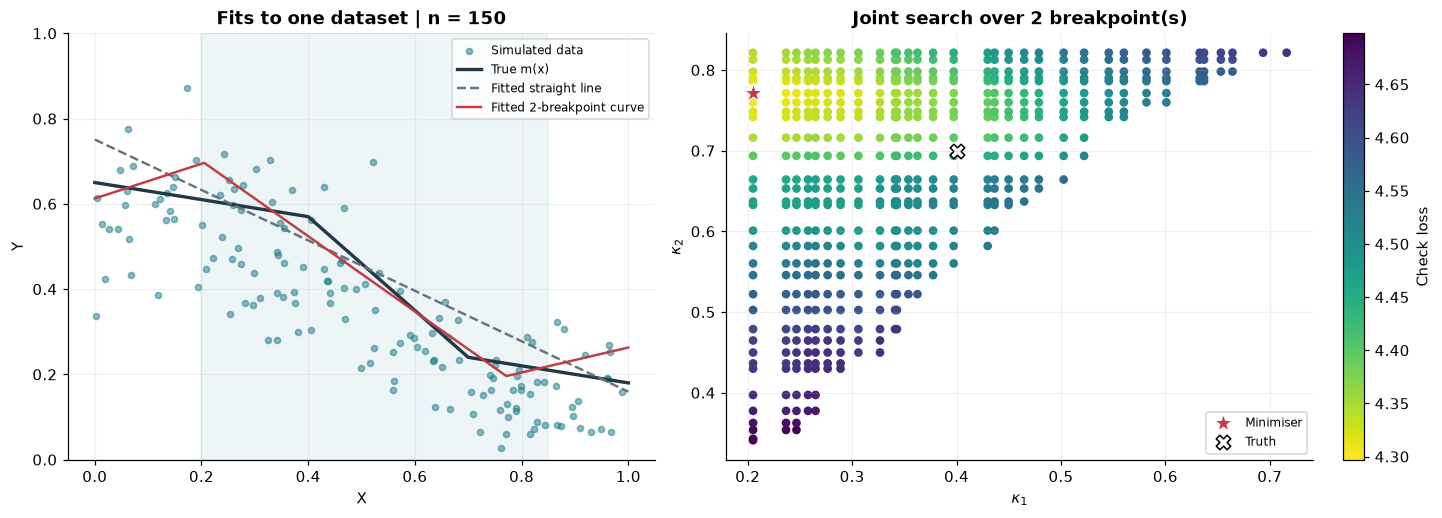

T_loss = 0.5959; minimum-loss number of breakpoints = 2; fitted breakpoints = [0.205, 0.771]; truth = [0.4, 0.7]


In [7]:
x, y = simulate(N_BASE, rng=rng_for('detector demo'))
result = fit_models(x, y, K_TEST, keep_profiles=True)
k_show = min(K_TEST, 2)
fit0, fit_k = result['fits'][0], result['fits'][k_show]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.axvspan(*KAPPA_WINDOW, color=C_DATA, alpha=0.07)
ax.scatter(x, y, s=16, alpha=0.5, color=C_DATA, label='Simulated data')
ax.plot(xx, m_true(xx), color=C_TRUE, lw=2.2, label='True m(x)')
ax.plot(xx, predict_fit(fit0, xx), color=C_NULL, ls='--', lw=1.6, label='Fitted straight line')
if fit_k is not None:
    ax.plot(xx, predict_fit(fit_k, xx), color=C_FIT, lw=1.6, label=f'Fitted {k_show}-breakpoint curve')
ax.set(title=f'Fits to one dataset | n = {N_BASE}', xlabel='X', ylabel='Y', ylim=(0, 1))
ax.legend(fontsize=8)

ax = axes[1]
profile = result['profiles'][k_show]
if profile.empty:
    ax.text(0.5, 0.5, 'No admissible candidate', transform=ax.transAxes, ha='center')
elif k_show == 1:
    ax.plot(profile.kappa_1, profile.loss, color=C_DATA)
    ax.scatter(fit_k['kappas'][0], fit_k['loss'], marker='*', s=180, color=C_FIT, edgecolor='white', zorder=3)
    if N_BREAKPOINTS == 1:
        ax.axvline(KAPPAS[0], color='black', ls=':', label='Truth')
    ax.set(xlabel=r'$\kappa_1$', ylabel='Check loss')
else:
    points = ax.scatter(profile.kappa_1, profile.kappa_2, c=profile.loss, s=22, cmap='viridis_r')
    fig.colorbar(points, ax=ax, label='Check loss')
    ax.scatter(*fit_k['kappas'], marker='*', s=180, color=C_FIT, edgecolor='white', label='Minimiser')
    if N_BREAKPOINTS == 2:
        ax.scatter(*KAPPAS, marker='X', s=90, color='white', edgecolor='black', label='Truth')
    ax.legend(fontsize=8, loc='lower right')
    ax.set(xlabel=r'$\kappa_1$', ylabel=r'$\kappa_2$')
ax.set_title(f'Joint search over {k_show} breakpoint(s)')
save_figure(fig, '03_detector_fit')
plt.show()

row = detector(x, y)
print(f"T_loss = {row['T_loss']:.4f}; minimum-loss number of breakpoints = {row['K_minloss']}; "
      f"fitted breakpoints = {np.round(fit_k['kappas'], 3).tolist() if fit_k else None}; truth = {list(KAPPAS)}")

## 4. Calibrated test at the baseline sample size

The hypotheses are

$$
H_0:\ \delta_1=\dots=\delta_K=0\ \ (m\text{ is a straight line})
\qquad\text{versus}\qquad
H_1:\ m\text{ has the breakpoints set in Section 0}.
$$

Three independent sets of simulated datasets are used.

**Step 1, calibration.** Simulate $R_{\mathrm{cal}}$ datasets from the null line $m_0$, compute $T_{\mathrm{loss}}$ for each, and take an upper order statistic as the critical value:

$$
\ell_\alpha=\big\lceil (R_{\mathrm{cal}}+1)(1-\alpha)\big\rceil,
\qquad
\widehat c_\alpha=T^{\mathrm{cal}}_{(\ell_\alpha)},
\qquad
\phi_\alpha(D_n)=\mathbf 1\{T_{\mathrm{loss}}(D_n)>\widehat c_\alpha\}.
$$

With $R_{\mathrm{cal}}=300$ and $\alpha=0.05$, $\ell_\alpha=286$, and the expected null rejection rate is $15/301\approx0.0498$.

**Step 2, Type-I error.** Simulate $R_{\mathrm{null}}$ fresh null datasets and report $\widehat\alpha=R_{\mathrm{null}}^{-1}\sum_r\phi_\alpha(D^{(r)})$.

**Step 3, power.** Simulate $R_{\mathrm{alt}}$ datasets from $m$ and report

$$
\widehat\pi=\frac{1}{R_{\mathrm{alt}}}\sum_{r=1}^{R_{\mathrm{alt}}}\phi_\alpha\big(D^{(r)}\big).
$$

Rates come with Wilson 95% Monte Carlo intervals. These are conditional on the calibrated cutoff, so a Type-I error a little away from 0.05 is expected.

**Why calibration uses the exact null line.** The spread of $Y$ around $m(x)$ is about $m(1-m)\sigma(x)$, which depends on the curve itself. So the null distribution of $T_{\mathrm{loss}}$ depends on which straight line is true. The cutoff is therefore calibrated under the specific null $m_0$. It is recalibrated whenever the sample size or the design of $X$ changes (Sections 6 and 7).

**Breakpoint location.** When $K\le K_{\mathrm{test}}$, the second table gives the bias and RMSE of $\widehat\kappa_j$ from the fit with the true number of breakpoints, over all fits and over rejected fits only. It also gives how often the true $\kappa$'s were admissible.

In [8]:
def one_replicate(n, deltas, near_share, half_width, phase, r):
    # Each replicate has its own random stream, so results do not depend on N_JOBS or finishing order.
    rng = rng_for('monte carlo', n, deltas, near_share, half_width, phase, r)
    x, y = simulate(n, deltas, rng=rng, near_share=near_share, half_width=half_width)
    row = detector(x, y)
    row['true_kappas_admissible'] = admissible(x, KAPPAS)
    return row


def monte_carlo(n, deltas, R, phase, near_share=None, half_width=None):
    deltas = tuple(float(d) for d in deltas)
    tasks = (delayed(one_replicate)(n, deltas, near_share, half_width, phase, r) for r in range(R))
    return pd.DataFrame(Parallel(n_jobs=N_JOBS)(tasks))


def critical_value(null_statistics, alpha=ALPHA):
    """c_alpha = T_(l) with l = ceil((R + 1)(1 - alpha)); +inf if l > R."""
    values = np.sort(np.asarray(null_statistics, float))
    rank = int(np.ceil((len(values) + 1) * (1 - alpha)))
    return (float(values[rank - 1]) if rank <= len(values) else np.inf), rank


def rate_summary(rejected, name):
    """Rejection rate with its Monte Carlo s.e. and Wilson 95% interval, keyed by name."""
    rejected = np.asarray(rejected, bool)
    R, p, z = len(rejected), rejected.mean(), stats.norm.ppf(0.975)
    center = (p + z * z / (2 * R)) / (1 + z * z / R)
    half = z * np.sqrt(p * (1 - p) / R + z * z / (4 * R * R)) / (1 + z * z / R)
    return {name: p, f'{name}_se': np.sqrt(p * (1 - p) / R),
            f'{name}_low': min(p, max(0, center - half)), f'{name}_high': max(p, min(1, center + half))}


def localization_summary(results, cutoff):
    """Bias and RMSE of kappa-hat from the fit with the true number of breakpoints."""
    K = N_BREAKPOINTS
    if K > K_TEST:
        return {}
    est = results[[f'kappa_{j}_fit_K{K}' for j in range(1, K + 1)]].to_numpy()
    valid = np.isfinite(est).all(axis=1)
    rejected = valid & (results.T_loss.to_numpy() > cutoff)
    out = dict(true_kappas_admissible=results.true_kappas_admissible.mean())
    for j in range(K):
        err = est[:, j] - KAPPAS[j]
        for label, mask in [('all', valid), ('rejected', rejected)]:
            out[f'kappa{j + 1}_bias_{label}'] = err[mask].mean() if mask.any() else np.nan
            out[f'kappa{j + 1}_rmse_{label}'] = np.sqrt((err[mask] ** 2).mean()) if mask.any() else np.nan
    return out


def run_test(n, near_share=None, half_width=None):
    """Calibrate the cutoff under H0, then estimate Type-I error and power for one design."""
    started = time.perf_counter()
    design = dict(near_share=near_share, half_width=half_width)
    calibration = monte_carlo(n, NULL_DELTAS, R_CAL, 'calibration', **design)
    cutoff, rank = critical_value(calibration.T_loss)
    null = monte_carlo(n, NULL_DELTAS, R_NULL, 'null', **design)
    alt = monte_carlo(n, DELTAS, R_ALT, 'alternative', **design)
    summary = dict(n=n, near_share=near_share, c_alpha=cutoff,
                   **rate_summary(null.T_loss > cutoff, 'type_I'),
                   **rate_summary(alt.T_loss > cutoff, 'power'),
                   **localization_summary(alt, cutoff))
    label = f'n = {n}' + ('' if near_share is None else f', near share = {near_share}')
    print(f'{label}: done in {time.perf_counter() - started:.0f}s', flush=True)
    return dict(calibration=calibration, null=null, alt=alt, c_alpha=cutoff, rank=rank, summary=summary)


def with_ci(table, rates=('type_I', 'power')):
    """Show each rate as 'rate [Wilson 95% CI]'."""
    out = table.copy()
    for r in rates:
        if r in out:
            out[r] = [f'{p:.3f} [{lo:.3f}, {hi:.3f}]'
                      for p, lo, hi in zip(table[r], table[f'{r}_low'], table[f'{r}_high'])]
            out = out.drop(columns=[f'{r}_se', f'{r}_low', f'{r}_high'])
    return out


def plot_rate(ax, x, table, rate, color, label, **kwargs):
    yerr = np.vstack([table[rate] - table[f'{rate}_low'], table[f'{rate}_high'] - table[rate]]).clip(min=0)
    ax.errorbar(x, table[rate], yerr=yerr, color=color, marker='o', ms=5, lw=1.6, capsize=3,
                label=label, **kwargs)

In [9]:
baseline = None
if RUN_MONTE_CARLO:
    baseline = run_test(N_BASE)
    print(f'Critical-value rank l_alpha = {baseline["rank"]} of R_cal = {R_CAL}')
    summary = pd.DataFrame([baseline['summary']])
    display(with_ci(summary)[['n', 'c_alpha', 'type_I', 'power']])
    display(summary.filter(regex='^(true_kappas|kappa)'))
else:
    print('Monte Carlo not run: set RUN_MONTE_CARLO = True.')

n = 150: done in 35s


Critical-value rank l_alpha = 286 of R_cal = 300


,n,c_alpha,type_I,power
0,150,0.3372,"0.063 [0.041, 0.097]","0.670 [0.615, 0.721]"


,true_kappas_admissible,kappa1_bias_all,kappa1_rmse_all,kappa1_bias_rejected,kappa1_rmse_rejected,kappa2_bias_all,kappa2_rmse_all,kappa2_bias_rejected,kappa2_rmse_rejected
0,1.0,-0.0016,0.092,-0.0007,0.0864,-0.0198,0.0873,-0.0158,0.0737


Empirical CDFs of $T_{\mathrm{loss}}$ under $H_0$ and $H_1$. The red dashed line is $\widehat c_\alpha$. Each curve's rejection rate is the share of its mass to the right of that line, i.e. one minus the curve's height at the cutoff.

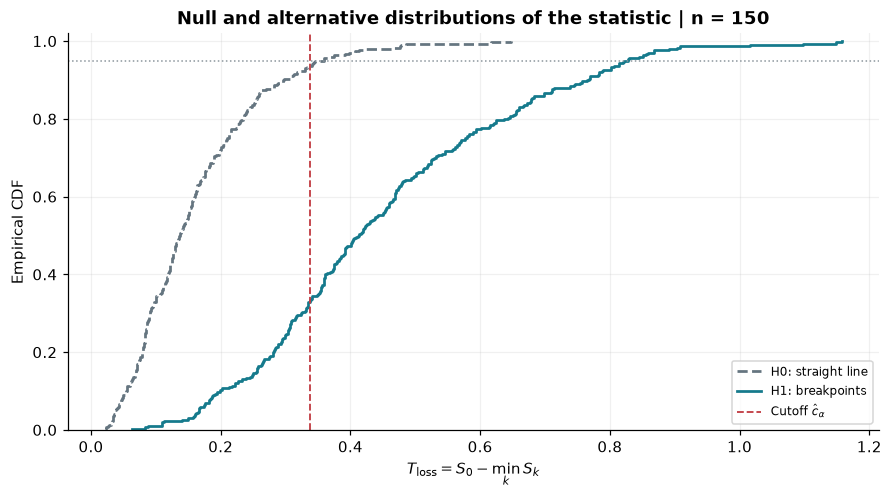

In [10]:
if RUN_MONTE_CARLO:
    fig, ax = plt.subplots(figsize=(8, 4.4))
    for table, color, ls, label in [(baseline['null'], C_NULL, '--', 'H0: straight line'),
                                    (baseline['alt'], C_DATA, '-', 'H1: breakpoints')]:
        values = np.sort(table.T_loss.to_numpy())
        ax.step(values, np.arange(1, len(values) + 1) / len(values), where='post',
                color=color, ls=ls, lw=1.8, label=label)
    ax.axvline(baseline['c_alpha'], color=C_FIT, ls='--', lw=1.2, label=r'Cutoff $\hat c_\alpha$')
    ax.axhline(1 - ALPHA, color=C_BAND, ls=':', lw=1)
    ax.set(title=f'Null and alternative distributions of the statistic | n = {N_BASE}',
           xlabel=r'$T_{\mathrm{loss}} = S_0 - \min_k S_k$', ylabel='Empirical CDF', ylim=(0, 1.02))
    ax.legend(fontsize=8, loc='lower right')
    save_figure(fig, '04_test_statistic_cdf')
    plt.show()

## 5. Power vs slope-change strength

Set the slope changes in `STRENGTH_SCENARIOS` at the top of the next cell. Each scenario is one tuple $(\delta_1,\dots,\delta_K)$ with **one value per breakpoint**, so the breakpoints can be strengthened together or separately. For example, $(-0.6,\,0)$ keeps only the first bend. Each scenario replaces $\delta$ in

$$
m_{\delta}(x)=\beta_0+\beta_1x+\sum_{j=1}^{K}\delta_j\,(x-\kappa_j)_+ ,
$$

and everything else stays fixed: breakpoint locations, $\beta_0$, $\beta_1$, $\sigma(x)$, the design of $X$, the sample size and the detector.

- The null line does not change with $\delta$, so one cutoff serves every scenario. At `STRENGTH_N = N_BASE` it is the cutoff from Section 4; at any other $n$ it is recalibrated once.
- A scenario of all zeros is the null itself, so its rejection rate is a Type-I error check.
- Every scenario must keep $m_\delta(x)$ inside $(0,1)$; the cell checks this before simulating.

,slope_changes,n,c_alpha,power
0,"(0, 0)",150,0.3372,"0.057 [0.036, 0.089]"
1,"(-0.3, 0.3)",150,0.3372,"0.070 [0.046, 0.105]"
2,"(-0.6, 0.6)",150,0.3372,"0.307 [0.257, 0.361]"
3,"(-0.9, 0.9)",150,0.3372,"0.670 [0.615, 0.721]"
4,"(-1.2, 1.2)",150,0.3372,"0.967 [0.940, 0.982]"


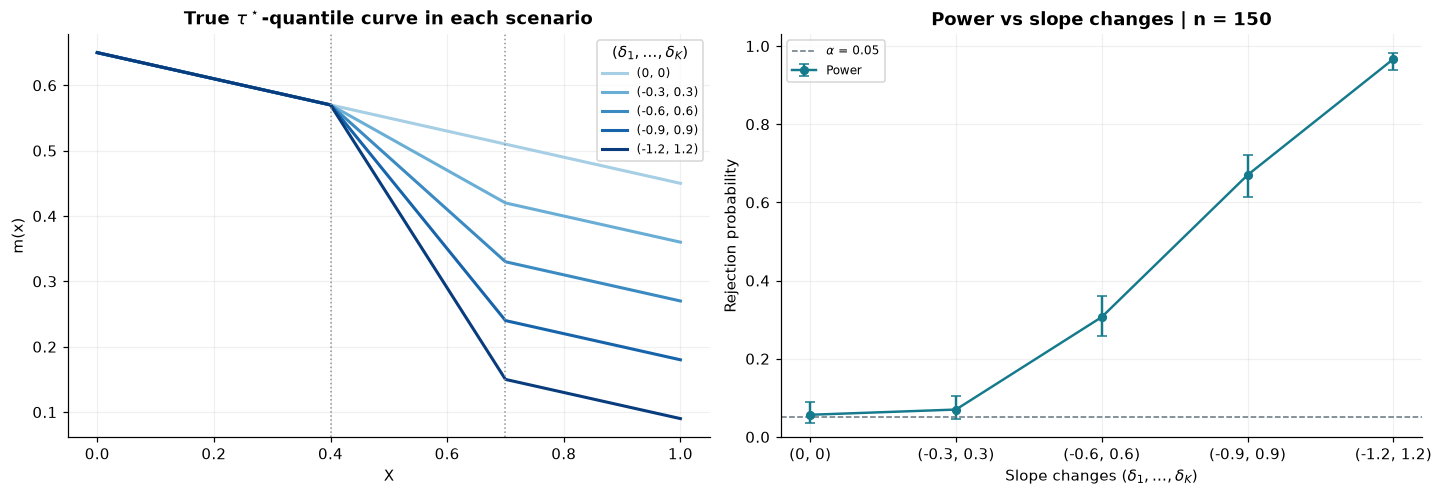

In [11]:
# One tuple per scenario, one slope change per breakpoint: (delta_1, ..., delta_K).
STRENGTH_SCENARIOS = [(0.00, 0.00), (-0.30, 0.30), (-0.60, 0.60), (-0.90, 0.90), (-1.20, 1.20)]
STRENGTH_N = N_BASE

for deltas in STRENGTH_SCENARIOS:
    assert len(deltas) == N_BREAKPOINTS, f'{deltas}: needs one slope change per breakpoint ({N_BREAKPOINTS}).'
    m = m_true(xx, deltas)
    assert (m > 0).all() and (m < 1).all(), f'{deltas}: m(x) leaves (0, 1); use smaller slope changes.'
labels = ['(' + ', '.join(f'{d:g}' for d in deltas) + ')' for deltas in STRENGTH_SCENARIOS]
shades = plt.cm.Blues(np.linspace(0.35, 0.95, len(STRENGTH_SCENARIOS)))

strength_summary = pd.DataFrame()
if RUN_MONTE_CARLO:
    if STRENGTH_N == N_BASE:
        cutoff = baseline['c_alpha']
    else:
        cutoff = critical_value(monte_carlo(STRENGTH_N, NULL_DELTAS, R_CAL, 'calibration').T_loss)[0]
    rows = []
    for deltas, label in zip(STRENGTH_SCENARIOS, labels):
        reuse = STRENGTH_N == N_BASE and np.allclose(deltas, DELTAS)
        table = baseline['alt'] if reuse else monte_carlo(STRENGTH_N, deltas, R_ALT, 'alternative')
        rows.append(dict(slope_changes=label, n=STRENGTH_N, c_alpha=cutoff,
                         **rate_summary(table.T_loss > cutoff, 'power')))
    strength_summary = pd.DataFrame(rows)
    display(with_ci(strength_summary))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    ax = axes[0]
    for deltas, label, shade in zip(STRENGTH_SCENARIOS, labels, shades):
        ax.plot(xx, m_true(xx, deltas), color=shade, lw=2, label=label)
    for k in KAPPAS:
        ax.axvline(k, color=C_BAND, ls=':', lw=1)
    ax.set(title=r'True $\tau^\star$-quantile curve in each scenario', xlabel='X', ylabel='m(x)')
    ax.legend(title=r'$(\delta_1, \ldots, \delta_K)$', fontsize=8)

    ax = axes[1]
    positions = np.arange(len(STRENGTH_SCENARIOS))
    plot_rate(ax, positions, strength_summary, 'power', C_DATA, 'Power')
    ax.axhline(ALPHA, color=C_NULL, ls='--', lw=1, label=rf'$\alpha$ = {ALPHA}')
    ax.set_xticks(positions, labels)
    ax.set(title=f'Power vs slope changes | n = {STRENGTH_N}', xlabel=r'Slope changes $(\delta_1, \ldots, \delta_K)$',
           ylabel='Rejection probability', ylim=(0, 1.03))
    ax.legend(fontsize=8)
    save_figure(fig, '05_power_vs_strength')
    plt.show()
else:
    print('Strength experiment not run: set RUN_MONTE_CARLO = True.')

## 6. Power vs sample size

Set the sample sizes in `SAMPLE_SIZES` at the top of the next cell. For every $n$, the whole procedure of Section 4 is repeated: a fresh null calibration, then independent null and alternative samples. The true curve, $\sigma(x)$, $\Psi$ and the design of $X$ stay fixed.

Two things change with $n$ at once:
- **Information grows,** so power should rise.
- **The admissible search set changes.** Each segment needs $h(n)=\max\{10,\lceil0.15n\rceil\}$ points, which is 25% of the data at $n=40$. Small samples therefore rule out more breakpoint tuples.

Small dips between neighbouring $n$ are usually Monte Carlo noise; check them against the intervals before reading anything into them.

n = 40: done in 4s


n = 60: done in 25s


n = 80: done in 34s


n = 100: done in 39s


n = 200: done in 51s


n = 300: done in 63s


,n,c_alpha,type_I,power
0,40,0.2583,"0.053 [0.033, 0.085]","0.247 [0.201, 0.298]"
1,60,0.3207,"0.010 [0.003, 0.029]","0.303 [0.254, 0.358]"
2,80,0.3290,"0.033 [0.018, 0.060]","0.410 [0.356, 0.466]"
3,100,0.3144,"0.053 [0.033, 0.085]","0.530 [0.474, 0.586]"
4,150,0.3372,"0.063 [0.041, 0.097]","0.670 [0.615, 0.721]"
5,200,0.3412,"0.020 [0.009, 0.043]","0.837 [0.791, 0.874]"
6,300,0.3333,"0.063 [0.041, 0.097]","0.943 [0.911, 0.964]"


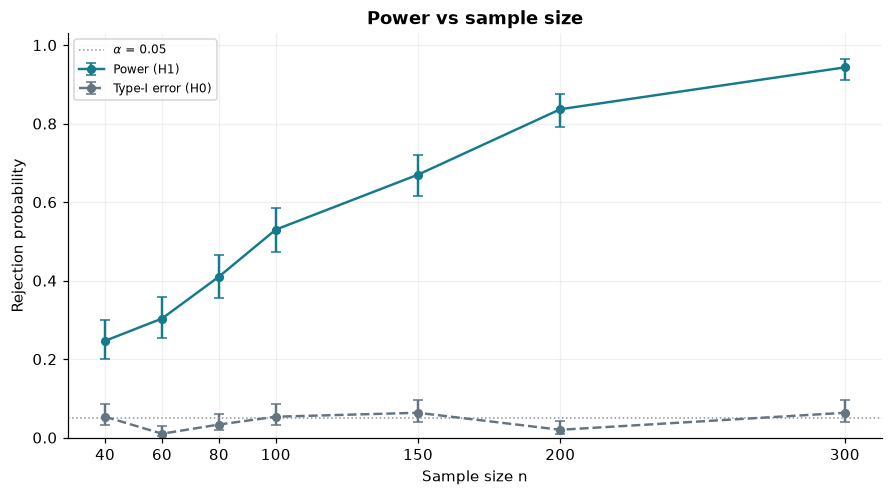

In [12]:
SAMPLE_SIZES = [40, 60, 80, 100, 150, 200, 300]

sample_size_summary = pd.DataFrame()
if RUN_MONTE_CARLO:
    sample_size_summary = pd.DataFrame([(baseline if n == N_BASE else run_test(n))['summary']
                                        for n in SAMPLE_SIZES])
    display(with_ci(sample_size_summary)[['n', 'c_alpha', 'type_I', 'power']])

    fig, ax = plt.subplots(figsize=(8, 4.4))
    plot_rate(ax, sample_size_summary.n, sample_size_summary, 'power', C_DATA, 'Power (H1)')
    plot_rate(ax, sample_size_summary.n, sample_size_summary, 'type_I', C_NULL, 'Type-I error (H0)', ls='--')
    ax.axhline(ALPHA, color=C_BAND, ls=':', lw=1, label=rf'$\alpha$ = {ALPHA}')
    ax.set(title='Power vs sample size', xlabel='Sample size n', ylabel='Rejection probability',
           ylim=(0, 1.03), xticks=SAMPLE_SIZES)
    ax.legend(fontsize=8)
    save_figure(fig, '06_power_vs_sample_size')
    plt.show()
else:
    print('Sample-size experiment not run: set RUN_MONTE_CARLO = True.')

## 7. Power vs sample density near the breakpoints

This experiment changes how many observations fall **near** the breakpoints while keeping the true curve, the noise and the sample size fixed. Two settings at the top of the next cell control it:

- `NEAR_HALF_WIDTH` $=w$ sets the window around each breakpoint:
  $$N_w=\bigcup_{j=1}^{K}\,[\kappa_j-w,\ \kappa_j+w].$$
- `NEAR_SHARES` lists the shares $p=P(X\in N_w)$ to compare, from very sparse ($p=0.05$) to very dense.

For each $p$, $X$ keeps the shape $g$ of the base design inside and outside the windows, but the total mass inside is set to $p$:

$$
g_p(x)=\frac{p}{G(N_w)}\,g(x)\,\mathbf 1\{x\in N_w\}
+\frac{1-p}{1-G(N_w)}\,g(x)\,\mathbf 1\{x\notin N_w\}.
$$

Here $G(N_w)$ is the share under the base design, so $p=G(N_w)$ gives back the base design. Draws are i.i.d.: each $X_i$ lands in $N_w$ with probability $p$.

The null calibration uses the **same** $g_p$, because the null distribution of $T_{\mathrm{loss}}$ depends on the design of $X$. The cutoff is therefore recalibrated for every $p$.

Two effects pull in opposite directions. Points near $\kappa_j$ pin down **where** the slope changes. Points far from $\kappa_j$ pin down the slopes on either side, and the hinge term $(x-\kappa_j)_+$ is close to 0 near $\kappa_j$. The power curve shows which effect dominates for this scenario, and the location columns show how localization changes.

Under the base design, 0.200 of X lies within 0.05 of a breakpoint.


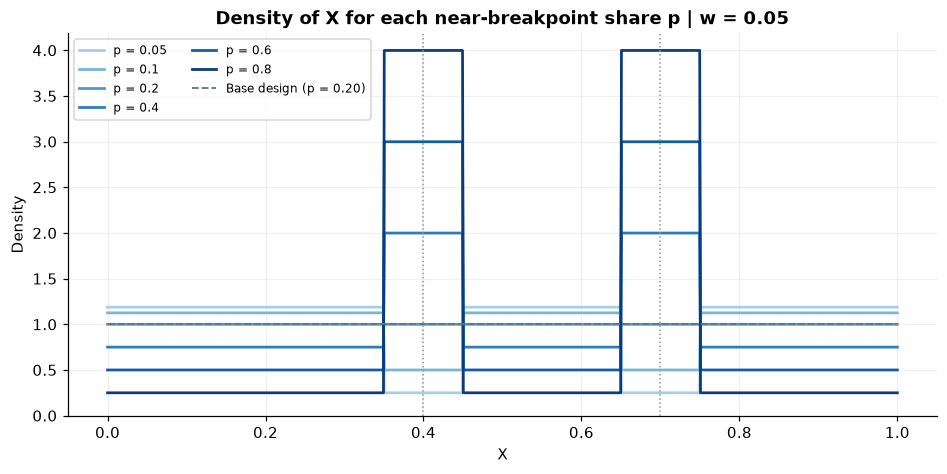

In [13]:
NEAR_HALF_WIDTH = 0.05                                 # w: window [kappa_j - w, kappa_j + w] around each breakpoint
NEAR_SHARES     = [0.05, 0.10, 0.20, 0.40, 0.60, 0.80]  # p = P(X in the windows), from very sparse to very dense
SPARSITY_N      = N_BASE                               # sample size for this experiment

base_share = near_breakpoints(x_big, NEAR_HALF_WIDTH).mean()   # G(N_w) under the base design
print(f'Under the base design, {base_share:.3f} of X lies within {NEAR_HALF_WIDTH} of a breakpoint.')

# Density of X for each share p
lo, hi = X_RANGE
g = stats.beta(*X_BETA).pdf((xx - lo) / (hi - lo)) / (hi - lo)
inside = near_breakpoints(xx, NEAR_HALF_WIDTH)
shades = plt.cm.Blues(np.linspace(0.35, 0.95, len(NEAR_SHARES)))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for p, shade in zip(NEAR_SHARES, shades):
    ax.plot(xx, np.where(inside, p / base_share, (1 - p) / (1 - base_share)) * g, color=shade, lw=1.8, label=f'p = {p:g}')
ax.plot(xx, g, color=C_NULL, ls='--', lw=1.2, label=f'Base design (p = {base_share:.2f})')
for k in KAPPAS:
    ax.axvline(k, color=C_BAND, ls=':', lw=1)
ax.set(title=f'Density of X for each near-breakpoint share p | w = {NEAR_HALF_WIDTH}',
       xlabel='X', ylabel='Density', ylim=(0, None))
ax.legend(fontsize=8, ncol=2)
save_figure(fig, '07_x_density_by_near_share')
plt.show()

One simulated dataset from $H_1$ in the **sparse** case, $p=\min(\texttt{NEAR\_SHARES})$.

- Red points fall within $w$ of a breakpoint, inside the shaded windows. Teal points fall outside.
- The ticks along the bottom mark where $X$ was sampled, so gaps around the breakpoints are easy to see.

Set `SHOW_SHARE` to any other share to view that case.

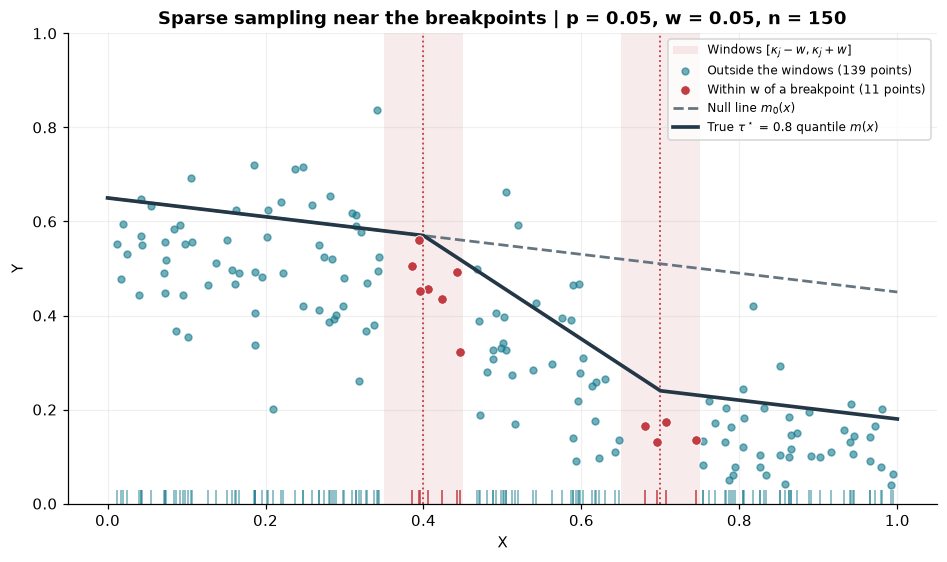

In [14]:
SHOW_SHARE = min(NEAR_SHARES)    # share p to visualise; min(NEAR_SHARES) is the sparsest case

x, y = simulate(SPARSITY_N, rng=rng_for('sparse illustration', SHOW_SHARE),
                near_share=SHOW_SHARE, half_width=NEAR_HALF_WIDTH)
near = near_breakpoints(x, NEAR_HALF_WIDTH)

fig, ax = plt.subplots(figsize=(8.5, 5))
for j, k in enumerate(KAPPAS):
    ax.axvspan(k - NEAR_HALF_WIDTH, k + NEAR_HALF_WIDTH, color=C_FIT, alpha=0.10, lw=0,
               label=r'Windows $[\kappa_j - w, \kappa_j + w]$' if j == 0 else None)
    ax.axvline(k, color=C_FIT, ls=':', lw=1.2)
ax.scatter(x[~near], y[~near], s=20, alpha=0.6, color=C_DATA, label=f'Outside the windows ({(~near).sum()} points)')
ax.scatter(x[near], y[near], s=40, color=C_FIT, edgecolor='white', lw=0.6, zorder=3,
           label=f'Within w of a breakpoint ({near.sum()} points)')
ax.plot(x[~near], np.full((~near).sum(), 0.015), '|', ms=9, color=C_DATA, alpha=0.6)
ax.plot(x[near], np.full(near.sum(), 0.015), '|', ms=9, color=C_FIT)
ax.plot(xx, m_true(xx, NULL_DELTAS), color=C_NULL, ls='--', lw=1.8, label=r'Null line $m_0(x)$')
ax.plot(xx, m_true(xx), color=C_TRUE, lw=2.4, label=rf'True $\tau^\star$ = {TAU_STAR} quantile $m(x)$')
ax.set(xlabel='X', ylabel='Y', ylim=(0, 1),
       title=f'Sparse sampling near the breakpoints | p = {SHOW_SHARE:g}, w = {NEAR_HALF_WIDTH}, n = {SPARSITY_N}')
ax.legend(fontsize=8, loc='upper right')
save_figure(fig, '08_sparse_sampling_example')
plt.show()

n = 150, near share = 0.05: done in 40s


n = 150, near share = 0.1: done in 42s


n = 150, near share = 0.2: done in 43s


n = 150, near share = 0.4: done in 44s


n = 150, near share = 0.6: done in 45s


n = 150, near share = 0.8: done in 45s


,near_share,n,c_alpha,type_I,power,kappa1_bias_all,kappa1_rmse_all,kappa2_bias_all,kappa2_rmse_all
0,0.05,150,0.3126,"0.057 [0.036, 0.089]","0.597 [0.540, 0.651]",-0.0091,0.1043,-0.0075,0.1092
1,0.10,150,0.3681,"0.030 [0.016, 0.056]","0.530 [0.474, 0.586]",-0.0035,0.0951,-0.0145,0.1012
2,0.20,150,0.3345,"0.043 [0.025, 0.073]","0.653 [0.598, 0.705]",0.0033,0.0873,-0.0034,0.0850
3,0.40,150,0.3644,"0.030 [0.016, 0.056]","0.787 [0.737, 0.829]",0.0041,0.0838,-0.0280,0.0901
4,0.60,150,0.3160,"0.083 [0.057, 0.120]","0.883 [0.842, 0.915]",0.0279,0.0857,-0.0367,0.0855
5,0.80,150,0.3374,"0.047 [0.028, 0.077]","0.767 [0.716, 0.811]",0.0470,0.0950,-0.0523,0.0998


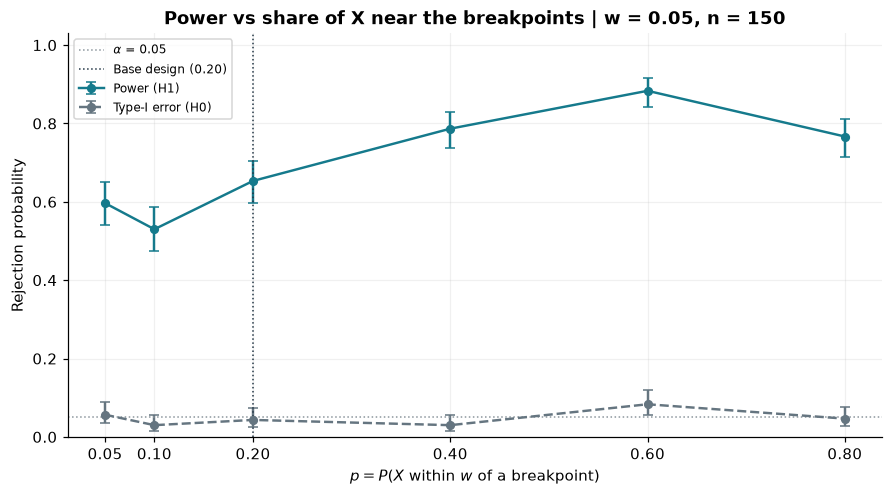

In [15]:
sparsity_summary = pd.DataFrame()
if RUN_MONTE_CARLO:
    sparsity_summary = pd.DataFrame([run_test(SPARSITY_N, near_share=p, half_width=NEAR_HALF_WIDTH)['summary']
                                     for p in NEAR_SHARES])
    display(with_ci(sparsity_summary)[['near_share', 'n', 'c_alpha', 'type_I', 'power']
                                      + [c for c in sparsity_summary if c.startswith('kappa') and 'all' in c]])

    fig, ax = plt.subplots(figsize=(8, 4.4))
    plot_rate(ax, sparsity_summary.near_share, sparsity_summary, 'power', C_DATA, 'Power (H1)')
    plot_rate(ax, sparsity_summary.near_share, sparsity_summary, 'type_I', C_NULL, 'Type-I error (H0)', ls='--')
    ax.axhline(ALPHA, color=C_BAND, ls=':', lw=1, label=rf'$\alpha$ = {ALPHA}')
    ax.axvline(base_share, color=C_TRUE, ls=':', lw=1, label=f'Base design ({base_share:.2f})')
    ax.set(title=f'Power vs share of X near the breakpoints | w = {NEAR_HALF_WIDTH}, n = {SPARSITY_N}',
           xlabel=r'$p = P(X$ within $w$ of a breakpoint$)$', ylabel='Rejection probability',
           ylim=(0, 1.03), xticks=NEAR_SHARES)
    ax.legend(fontsize=8)
    save_figure(fig, '09_power_vs_near_share')
    plt.show()
else:
    print('Sparsity experiment not run: set RUN_MONTE_CARLO = True.')

## 8. Notes

- **What is held fixed.** Every experiment changes one thing and keeps the rest of the scenario from Section 0: slope changes (Section 5), sample size (Section 6), or the share of $X$ near the breakpoints (Section 7).
- **When the cutoff is recalibrated.** The null distribution of $T_{\mathrm{loss}}$ depends on the null line, $\sigma(x)$, $n$ and the design of $X$, but not on $\delta$. So the cutoff is shared across strength scenarios and recalibrated for every $n$ and every $p$.
- **What a rejection means.** Rejecting linearity under a two-breakpoint truth does **not** show that there are exactly two breakpoints. Testing $K\le1$ against $K=2$ is a separate problem.
- **What the intervals cover.** Wilson intervals describe Monte Carlo error given the calibrated cutoff. Increase $R_{\mathrm{cal}}$, $R_{\mathrm{null}}$ and $R_{\mathrm{alt}}$ to narrow them; the run time grows in proportion.
- **Run time.** It is driven by the joint search: with $K_{\mathrm{test}}=2$ each dataset fits up to $\binom{41}{2}=820$ candidate pairs. $K_{\mathrm{test}}=3$ is possible but much slower.